In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os


In [ ]:
path = '/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Local_bits/mini2p test/stripes/MY_71_R'
# path = '/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Local_bits/mini2p test/meg_72L'

In [45]:
os.listdir(path)[-1]

'pretask_00005.tif'

In [ ]:
#find tiff files in the directory and list them
tiff_files = [f for f in os.listdir(path) if f.endswith('.tif')]

In [46]:
tiff_file = os.path.join(path, os.listdir(path)[-1])


In [47]:
#read the tiff header to get the dimensions
from PIL import Image
with Image.open(tiff_file) as img:
    width, height = img.size
    num_frames = img.n_frames
print(f'Tiff dimensions: {width}x{height}, Number of frames: {num_frames}')
#now read the tiff stack into a numpy array
tiff_stack = np.zeros((height, width, num_frames))
with Image.open(tiff_file) as img:
    for i in range(num_frames):
        img.seek(i)
        tiff_stack[:, :, i] = np.array(img)
print(f'Tiff stack shape: {tiff_stack.shape}')


Tiff dimensions: 512x512, Number of frames: 1000
Tiff stack shape: (512, 512, 1000)


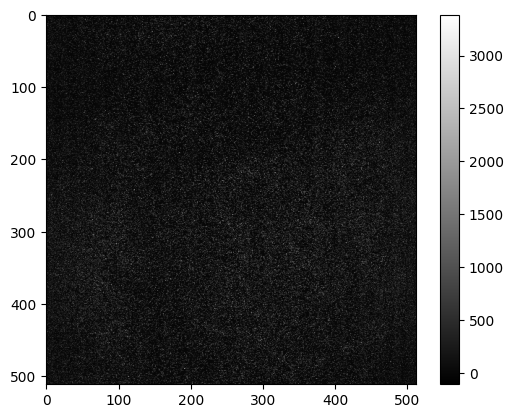

In [48]:
stack1 = tiff_stack[:, :, ::2]
stack2 = tiff_stack[:, :, 1::2]

test_img = stack1[:, :, 400]
plt.imshow(test_img, cmap='gray')
plt.colorbar()

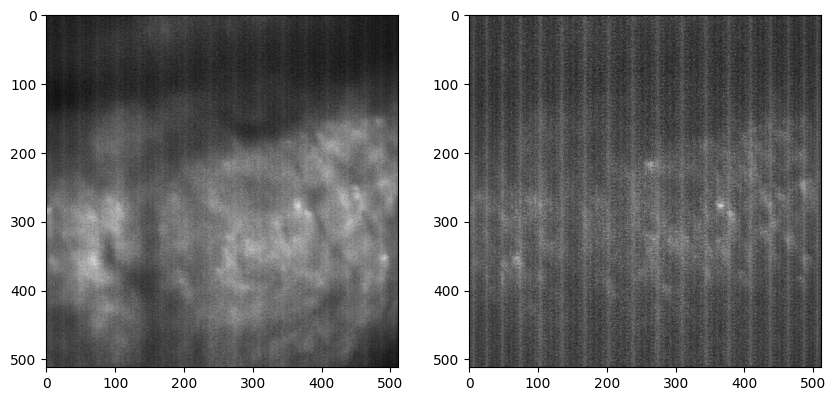

In [49]:
#normalize each frame by max and min and then average them all
new_stack1 = np.zeros_like(stack1)
for i in range(stack1.shape[2]):
    new_stack1[:, :, i] = (stack1[:, :, i] - np.min(stack1[:, :, i])) / (np.max(stack1[:, :, i]) - np.min(stack1[:, :, i]))
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.nanmean(new_stack1, axis=2), cmap='gray')
new_stack2 = np.zeros_like(stack2)
for i in range(stack2.shape[2]):
    new_stack2[:, :, i] = (stack2[:, :, i] - np.min(stack2[:, :, i])) / (np.max(stack2[:, :, i]) - np.min(stack2[:, :, i]))
plt.subplot(1, 2, 2)
plt.imshow(np.nanmean(new_stack2, axis=2), cmap='gray')

In [50]:
frame = 20

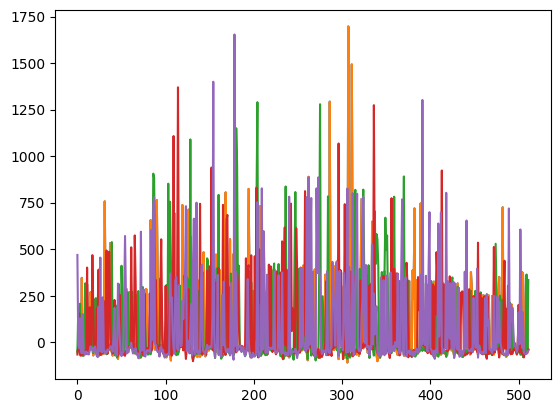

In [51]:
#take the first line of the first frame of stack1 and plot it
first_line = stack1[0, :, frame]
plt.plot(first_line)
#then attach the second line in reverse order to the end of the first line and plot that
second_line = stack1[1, ::-1, frame]
# second_line = stack1[1, :, frame]

third_line = stack1[2, :, frame]
fourth_line = stack1[3, ::-1, frame]
# fourth_line = stack1[3, :, frame]
all_lines = np.concatenate((first_line, second_line, third_line, fourth_line))
# plt.plot(all_lines)
plt.plot(np.arange(len(first_line)), first_line, label='forward')
plt.plot(np.arange(len(second_line)), second_line, label='reverse')
plt.plot(np.arange(len(third_line)), third_line, label='forward')
plt.plot(np.arange(len(fourth_line)), fourth_line, label='reverse')

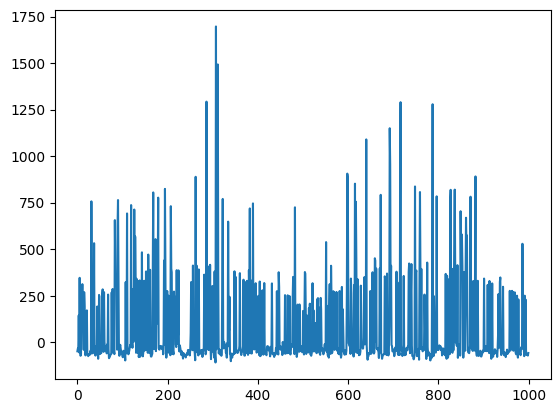

In [52]:
plt.plot(all_lines[:1000])

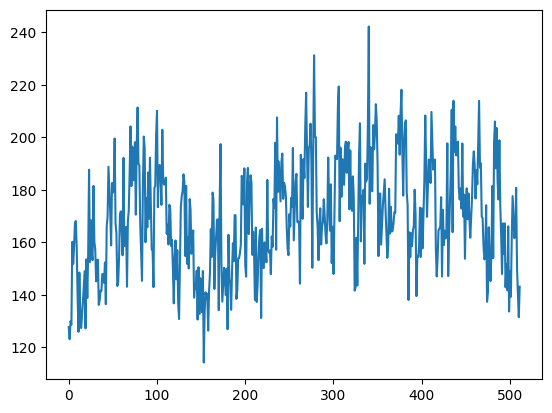

In [53]:
#average across lines to see if there are stripes
line_avg = np.nanmean(test_img, axis=0)
plt.plot(line_avg)

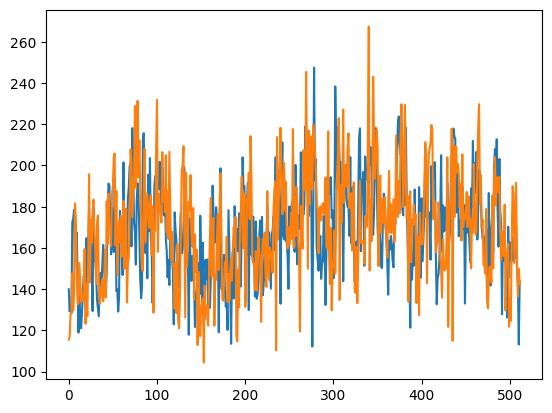

In [54]:
forward_lines = test_img[::2, :]
reverse_lines = test_img[1::2, :]
avg_forward = np.nanmean(forward_lines, axis=0)
avg_reverse = np.nanmean(reverse_lines, axis=0)
plt.plot(avg_forward, label='forward')
plt.plot(avg_reverse, label='reverse')

Lag: 0


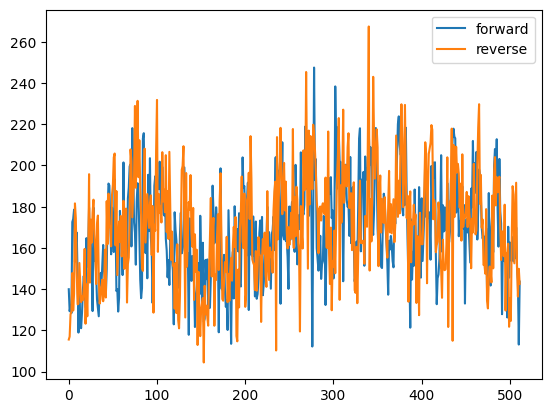

In [55]:
#calculate offset between forward and reverse lines

corr = np.correlate(avg_forward - np.mean(avg_forward), avg_reverse - np.mean(avg_reverse), mode='full')
lag = np.argmax(corr) - (len(avg_forward) - 1)
print(f'Lag: {lag}')
avg_reverse = np.roll(avg_reverse, lag)
plt.plot(avg_forward, label='forward')
plt.plot(avg_reverse, label='reverse')
plt.legend()

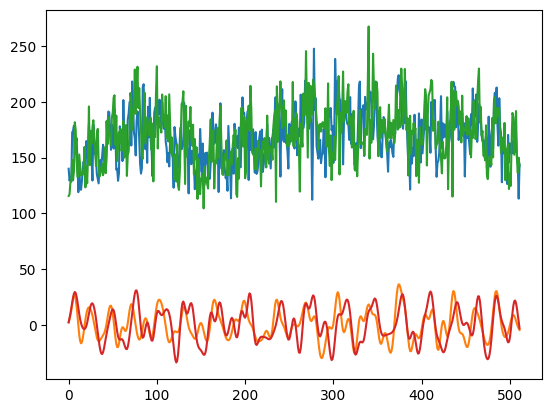

In [56]:
#fit a bandpass filter to the line average to see if it captures the stripes
from scipy.signal import butter, filtfilt
def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band', analog=False)
    return b, a
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = filtfilt(b, a, data)
    return y
lowcut = 0.01  # low cutoff frequency in Hz
highcut = 0.1  # high cutoff frequency in Hz
fs = 1.0  # sampling frequency in Hz (1 sample per pixel)
filtered_line_avg = butter_bandpass_filter(line_avg, lowcut, highcut, fs)
filtered_forward = butter_bandpass_filter(avg_forward, lowcut, highcut, fs)
filtered_reverse = butter_bandpass_filter(avg_reverse, lowcut, highcut, fs)
# plt.plot(line_avg, label='Line Average')
# plt.plot(filtered_line_avg, label='Filtered Line Average')
plt.plot(avg_forward, label='Forward Average')
plt.plot(filtered_forward, label='Filtered Forward Average')
plt.plot(avg_reverse, label='Reverse Average')
plt.plot(filtered_reverse, label='Filtered Reverse Average')

In [57]:
stack1.shape

(512, 512, 500)

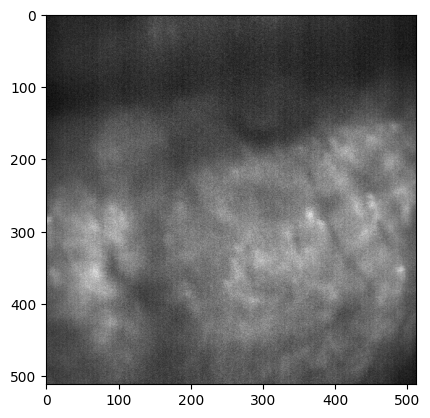

In [58]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack1 = np.zeros_like(stack1)
frame_forward = np.zeros([stack1.shape[0], stack1.shape[2]])
frame_reverse = np.zeros([stack1.shape[0], stack1.shape[2]])
for i in range(stack1.shape[2]):
    forward_lines = stack1[::2, :, i]
    reverse_lines = stack1[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    filtered_avg_forward = butter_bandpass_filter(avg_forward, lowcut, highcut, fs)
    filtered_avg_reverse = butter_bandpass_filter(avg_reverse, lowcut, highcut, fs)
    for j in range(stack1.shape[0]):
        if j % 2 == 0:
            detrended_stack1[j, :, i] = stack1[j, :, i] - filtered_avg_forward
        else:
            detrended_stack1[j, :, i] = stack1[j, :, i] - filtered_avg_reverse

plt.imshow(np.nanmean(detrended_stack1, axis=2), cmap='gray')

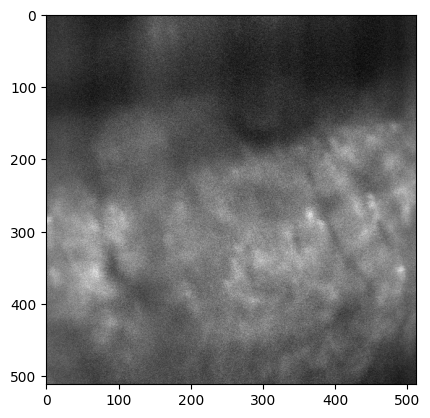

In [59]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack1 = np.zeros_like(stack1)
frame_forward = np.zeros([stack1.shape[0], stack1.shape[2]])
frame_reverse = np.zeros([stack1.shape[0], stack1.shape[2]])
for i in range(stack1.shape[2]):
    forward_lines = stack1[::2, :, i]
    reverse_lines = stack1[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack1.shape[0]):
        if j % 2 == 0:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_forward
        else:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack1, axis=2), cmap='gray')

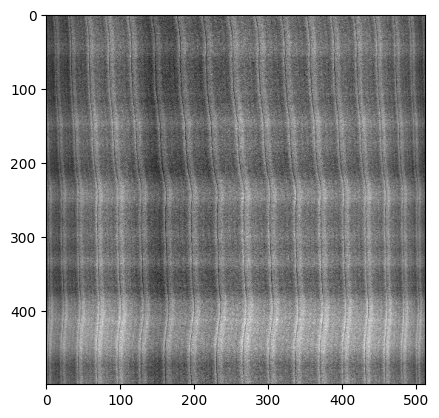

In [60]:
plt.imshow(frame_reverse.T, cmap='gray')

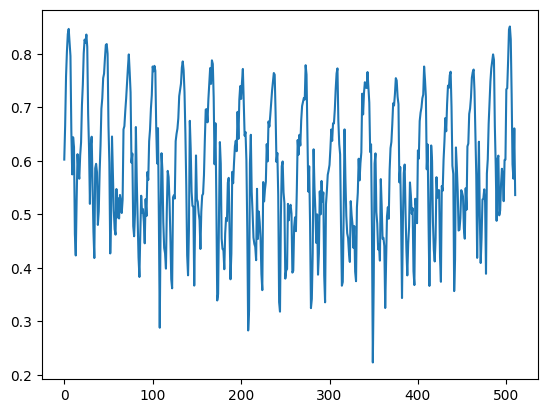

In [61]:
#correlate one row with the next row to see if the stripes are consistent across rows
corr_rows = np.zeros(stack1.shape[0] - 1)
for i in range(stack1.shape[0] - 1):
    row1 = frame_forward[i, :]
    row2 = frame_forward[i + 1, :]
    corr_rows[i] = np.corrcoef(row1, row2)[0, 1]
plt.plot(corr_rows)

In [65]:
#save this as a tiff stack
from PIL import Image
output_file = os.path.join(path, 'detrended_stack1.tiff')
with Image.fromarray(detrended_stack1[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack1[:, :, i]) for i in range(1, detrended_stack1.shape[2])])

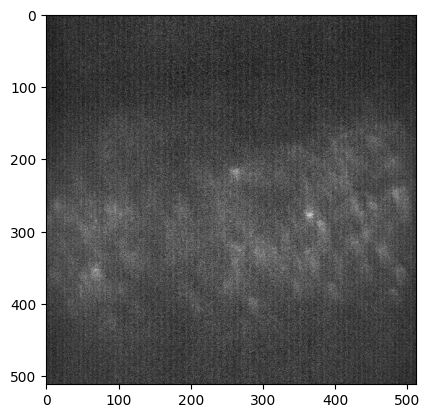

In [62]:
#do this detrending for the entire stack and plot the average to see if it removes the stripes
detrended_stack2 = np.zeros_like(stack2)
for i in range(stack2.shape[2]):
    forward_lines = stack2[::2, :, i]
    reverse_lines = stack2[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    filtered_avg_forward = butter_bandpass_filter(avg_forward, lowcut, highcut, fs)
    filtered_avg_reverse = butter_bandpass_filter(avg_reverse, lowcut, highcut, fs)
    for j in range(stack2.shape[0]):
        if j % 2 == 0:
            detrended_stack2[j, :, i] = stack2[j, :, i] - filtered_avg_forward
        else:
            detrended_stack2[j, :, i] = stack2[j, :, i] - filtered_avg_reverse

plt.imshow(np.nanmean(detrended_stack2, axis=2), cmap='gray')

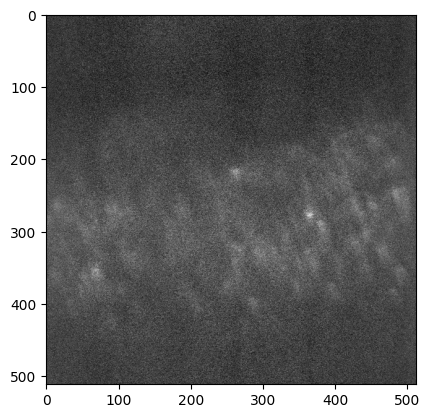

In [63]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack2 = np.zeros_like(stack2)
frame_forward = np.zeros([stack2.shape[0], stack2.shape[2]])
frame_reverse = np.zeros([stack2.shape[0], stack2.shape[2]])
for i in range(stack2.shape[2]):
    forward_lines = stack2[::2, :, i]
    reverse_lines = stack2[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack2.shape[0]):
        if j % 2 == 0:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_forward
        else:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack2, axis=2), cmap='gray')

In [64]:
#save this as a tiff stack
from PIL import Image
output_file = os.path.join(path, 'detrended_stack2.tiff')
with Image.fromarray(detrended_stack2[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack2[:, :, i]) for i in range(1, detrended_stack2.shape[2])])

In [280]:
#interleave a frame from stack1 and stack2 to get a new stack with the same dimensions as the original tiff stack
interleaved_stack = np.zeros_like(tiff_stack)
interleaved_stack[:, :, ::2] = detrended_stack1
interleaved_stack[:, :, 1::2] = detrended_stack2

#save this as a tiff stack
output_file = os.path.join(path, 'detrended_interleaved_stack.tiff')
with Image.fromarray(interleaved_stack[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(interleaved_stack[:, :, i]) for i in range(1, interleaved_stack.shape[2])])

## Notes on img parameters below

In [41]:
samples_per_line = line_period/sampling_rate
pixels_per_line = line_period/pixel_time
print(f'Samples per line: {samples_per_line}, Pixels per line: {pixels_per_line}')

Samples per line: 2e-12, Pixels per line: 1436.7816091954023


In [40]:
pixel_time = 0.000000174 #174 ns per pixel
line_time = pixel_time * width #time for one line
frame_time = line_time * height #time for one frame
print(f'Pixel time: {pixel_time} seconds, Line time: {line_time} seconds, Frame time: {frame_time} seconds')

Pixel time: 1.74e-07 seconds, Line time: 8.9088e-05 seconds, Frame time: 0.045613056 seconds


In [39]:
sampling_rate = 125000000 #125 MHz
line_period = 0.00025 #250 microseconds per line
lines_per_frame = height
frame_period = line_period * lines_per_frame #time for one frame
fly_back_time = 0.005 #5 ms flyback time
frame_period += fly_back_time #add flyback time to frame period
frame_rate = 1 / frame_period
print(f'Frame period: {frame_period} seconds, Frame rate: {frame_rate} Hz')

Frame period: 0.133 seconds, Frame rate: 7.518796992481203 Hz
